In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

atlas = 'Nettekoven_MADS'
rois = ['cerebellum_L', 'cerebellum_R']
colours = ['green', 'r', 'blue']

segment = 'GM'

# observed means
patients_actual = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}', f'summary_MNISymC_Nettekoven_MADS_{segment}_mod.tsv'), sep = '\t')
patients_actual = patients_actual[patients_actual.isPatient == 1]
controls_actual = pd.read_csv(os.path.join(gl.baseDir, f'MNISymC_{segment}', f'summary_MNISymC_Nettekoven_MADS_{segment}_mod.tsv'), sep = '\t')
controls_actual = controls_actual[controls_actual.isPatient == 0]

# estimated means
patients_lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', f'patients_MNISymC_{segment}_mod_Nettekoven_MADS_lme.tsv'), sep = '\t')
patients_lme = patients_lme.drop(columns = ['subj_id', 'random_intercept', 'Unnamed: 0']).drop_duplicates().reset_index(drop = True)
controls_lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', f'controls_MNISymC_{segment}_mod_Nettekoven_MADS_lme.tsv'), sep = '\t')
controls_lme = controls_lme.drop(columns = ['subj_id', 'random_intercept', 'Unnamed: 0']).drop_duplicates().reset_index(drop = True)



# get hemisphere
patients_lme['hemisphere'] = patients_lme.regionname.str.lower().str[-1]
controls_lme['hemisphere'] = controls_lme.regionname.str.lower().str[-1]
patients_actual['hemisphere'] = patients_actual.regionname.str.lower().str[-1]
controls_actual['hemisphere'] = controls_actual.regionname.str.lower().str[-1]


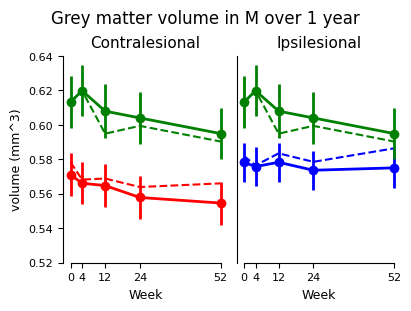

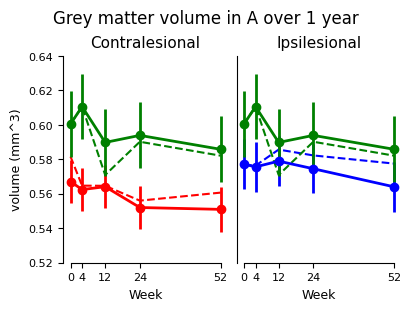

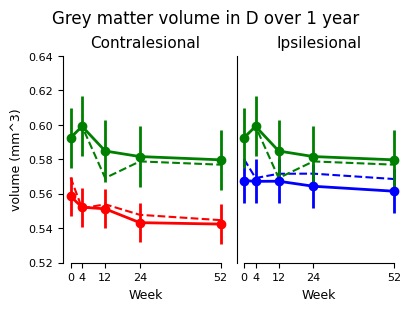

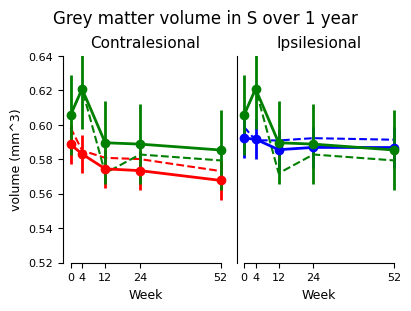

In [2]:
for roi in ['M', 'A', 'D', 'S']:
    fig, axs = plt.subplots(1, 2, figsize=(4, 3), sharey = True, constrained_layout = True)

    # for controls, get bihemispheric mean
    controls_lme_roi = controls_lme[controls_lme.regionname.str.startswith(roi)]
    controls_lme_roi = controls_lme_roi.groupby('Week').agg({'beta': 'mean', 'se': 'mean'}).reset_index().sort_values('Week')
    controls_actual_roi = controls_actual[controls_actual.regionname.str.startswith(roi)]
    controls_actual_roi = controls_actual_roi.groupby('Week').agg({'mean': 'mean'}).reset_index().sort_values('Week')

    patients_lme_roi = patients_lme[patients_lme.regionname.str.startswith(roi)].sort_values('Week')
    patients_actual_roi = patients_actual[patients_actual.regionname.str.startswith(roi)].sort_values('Week')


    for i, H in enumerate(gl.Hem):
        ax = axs[i]
        patients_lme_h = patients_lme_roi[patients_lme_roi.hemisphere == H].sort_values('Week')
        patients_actual_h = patients_actual_roi[patients_actual_roi.hemisphere == H].sort_values('Week')
        patients_actual_h = patients_actual_h.groupby(['Week'], as_index = False)['mean'].mean()

        ax.errorbar(x=patients_lme_h['Week'], y=patients_lme_h['beta'], yerr = patients_lme_h['se'], fmt = '-o', color = colours[i+1], linewidth = 2, label = 'patients')
        ax.plot(patients_actual_h['Week'], patients_actual_h['mean'], color = colours[i+1], linestyle = '--')



        ax.errorbar(x=controls_lme_roi['Week'], y=controls_lme_roi['beta'], yerr = controls_lme_roi['se'], fmt = '-o', color = 'green', linewidth = 2, label = 'controls')
        ax.plot(controls_actual_roi['Week'], controls_actual_roi['mean'], color = 'green', linestyle = '--',)

        ax.set_title("Contralesional" if H == 'l' else "Ipsilesional")

    for i in range(2):
        axs[i].set_xticks(gl.weeks)
        axs[i].set_xlabel("Week")
        axs[i].set_title(gl.side[i])
        axs[i].set_ylim([.52, .64])

    axs[1].tick_params(axis = 'y', length = 0)
    axs[0].set_ylabel('volume (mm^3)')

    fig.suptitle(f'Grey matter volume in {roi} over 1 year')
    sns.despine(trim = True)


    plt.show()